# Nettoyage du fichier bat_surveys
Les relevés doivent être comparables avant toute analyse. on vérifie les doublons, les formats, les valeurs manquantes et les dates. Je conserve les valeurs atypiques tant que rien ne prouve qu’elles sont erronées.

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import mlxtend

chargement des données

In [92]:
df = pd.read_csv("data/ecology/bat_surveys.csv")

## Vérification de la qualité des données 

Nombre de lignes et de colonnes

In [93]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 4994
Nombre de colonnes : 14


Noms des colonnes

In [94]:
# Noms des colonnes
print("\nNoms des colonnes :")
print(df.columns.tolist())


Noms des colonnes :
['survey_id', 'site_code', 'survey_start', 'survey_end', 'survey_method', 'observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'nightly_visit_count', 'colony_estimate', 'comparison_species_count', 'observer_team', 'survey_quality', 'weather_interference']


In [95]:
# 5 premières lignes
print("\n5 premières lignes :")
display(df.head())


5 premières lignes :


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
0,BAT-0000001,KNT-KES,2019-01-05T18:00:00,2019-01-12T00:00:00,fixed_acoustic_station,28.6,7,13,7,3.8,8,TEAM-11-2,high,32.0
1,BAT-0000002,KNT-KES,2019-02-05T18:00:00,2019-02-12T00:00:00,acoustic_and_visual,31.7,8,12,9,7.3,18,TEAM-11-2,acceptable,18.5
2,BAT-0000003,KNT-KES,2019-03-05T18:00:00,2019-03-12T00:00:00,fixed_acoustic_station,32.4,22,28,14,19.9,8,TEAM-11-2,high,26.2
3,BAT-0000004,KNT-KES,2019-04-05T18:00:00,2019-04-12T00:00:00,acoustic_and_visual,35.7,26,36,19,32.2,14,TEAM-11-2,high,35.0
4,BAT-0000005,KNT-KES,2019-05-05T18:00:00,2019-05-12T00:00:00,acoustic_transect,32.0,23,29,22,20.9,16,TEAM-11-2,acceptable,38.7


ce fichier des informations sur la période d'observation (dates de début et de fin, durée en heures, méthode employée), des indicateurs d'activité (nombre de chauves-souris observées, détections acoustiques, visites nocturnes, estimation de la colonie et espèces comparées), ainsi que le contexte logistique et environnemental (équipe d'observateurs, qualité de l'enquête et niveau d'interférence météo).

Nombre de valeurs manquantes par colonne

In [96]:

missing = df.isnull().sum()

print("Valeurs manquantes par colonne :")
display(missing)

Valeurs manquantes par colonne :


survey_id                    0
site_code                    0
survey_start                 0
survey_end                   0
survey_method                0
observation_hours            0
observed_bat_count           0
acoustic_detection_count     0
nightly_visit_count          0
colony_estimate              0
comparison_species_count     0
observer_team               20
survey_quality               0
weather_interference         0
dtype: int64

Nombre de doublons

In [97]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 2


Afficher les doublons

In [98]:
duplicates = df[df.duplicated(keep=False)]

display(duplicates)

,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
3182,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
3566,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9
4992,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
4993,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9


Vérification des valeurs et de leur fréquence dans les colonnes catégorielles

In [99]:
colonnes_categorielles = ['survey_method', 'survey_quality', 'site_code', 'observer_team']
for col in colonnes_categorielles:
    print(f"\n{col} :")
    print(df[col].value_counts(dropna=False).head(25))


survey_method :
survey_method
acoustic_and_visual       1743
acoustic_transect         1617
fixed_acoustic_station    1614
FIXED_ACOUSTIC_STATION       9
ACOUSTIC_AND_VISUAL          4
ACOUSTIC_TRANSECT            4
Fixed_Acoustic_Station       2
Acoustic_Transect            1
Name: count, dtype: int64

survey_quality :
survey_quality
high          2690
acceptable    2166
limited        138
Name: count, dtype: int64

site_code :
site_code
AVL-ABG    79
AVL-FNQ    79
KNT-KES    78
KNT-LUM    78
KNT-SEN    78
AVL-MAR    78
AVL-VEL    78
AVL-ORR    78
TMB-NAC    78
TMB-PEL    78
KNT-CYP    78
KNT-YRX    78
KNT-GKR    78
KNT-NNM    78
KNT-JAK    78
KNT-JQG    78
KNT-VLB    78
KNT-CHP    78
KNT-YRG    78
KNT-WUQ    78
KNT-DMJ    78
KNT-GGN    78
KNT-QWU    78
KNT-TLQ    78
KNT-UJJ    78
Name: count, dtype: int64

observer_team :
observer_team
TEAM-11-3    390
TEAM-11-4    390
TEAM-12-1    389
TEAM-11-2    388
TEAM-12-2    388
TEAM-12-4    314
TEAM-12-5    312
TEAM-13-3    311
TEAM-11-5    

Vérification des valeurs présentes dans les colonnes numériques

In [100]:
for col in ["observation_hours", "observed_bat_count", "acoustic_detection_count", "nightly_visit_count", "weather_interference", "colony_estimate", "comparison_species_count"]:
    print(col, "→", df[col].unique()[:30])

observation_hours → <StringArray>
['28.6', '31.7', '32.4', '35.7', '32.0', '23.5', '27.5', '23.1', '29.7',
 '32.2', '33.0', '30.1', '35.4', '43.5', '34.3', '27.3', '33.9', '23.2',
 '27.2', '25.6', '12.2', '28.1', '37.8', '34.5', '37.2', '32.7', '29.5',
 '25.8', '29.3', '35.3']
Length: 30, dtype: str
observed_bat_count → <StringArray>
[      '7',       '8',      '22',      '26',      '23',      '21',      '19',
      '13',      '10',      '18',      '16',      '17',      '28',      '31',
      '32', '9 count',      '11',       '9',      '24',      '25',      '38',
       '5',      '12',      '40',      '36',      '15',      '20',      '41',
      '33',       '3']
Length: 30, dtype: str
acoustic_detection_count → <StringArray>
['13', '12', '28', '36', '29', '39', '22', '15', '23', '31', '18', '27',  '5',
 '16', '26', '34', '47',  '6',  '3', '17', '14', '19', '38', '52', '10', '33',
 '24', '40', '45', '30']
Length: 30, dtype: str
nightly_visit_count → <StringArray>
[      '7',       '9', 

Identification des valeurs non numériques dans les colonnes

In [101]:
colonnes_numeriques = [
    'observation_hours',
    'observed_bat_count',
    'acoustic_detection_count',
    'nightly_visit_count',
    'colony_estimate',
    'comparison_species_count',
    'weather_interference'
]

In [102]:
for col in colonnes_numeriques:
    mask = pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()
    if mask.any():
        print(f"{col} → valeurs problématiques :", df.loc[mask, col].unique())

observation_hours → valeurs problématiques : <StringArray>
['24,3', '37,2', '30,6', '35,0', '34,3', '31,6', '31,2', '32,5', '23,5',
 '35,7', '28,1', '21,2', '36,8', '30,4', '37,8', '24,0', '27,8', '24,9',
 '17,3', '32,1', '30,3', '28,5', '23,6', '26,3', '32,4', '32,2', '38,0',
 '36,2', '36,4', '36,9']
Length: 30, dtype: str
observed_bat_count → valeurs problématiques : <StringArray>
[ '9 count', '11 count', '16 count', '18 count',  '5 count', '10 count',
  '1 count',  '4 count', '19 count', '17 count',  '6 count', '30 count',
 '13 count',  '7 count', '20 count']
Length: 15, dtype: str
acoustic_detection_count → valeurs problématiques : <StringArray>
[ '7 count', '52 count', '47 count', '13 count', '18 count', '23 count',
 '37 count', '14 count',  '9 count',  '3 count', '28 count', '25 count',
 '33 count', '21 count', '41 count', '27 count', '12 count', '30 count',
 '16 count', '22 count', '26 count', '32 count']
Length: 22, dtype: str
nightly_visit_count → valeurs problématiques : <Str

## Nettoyage des données

Suppression des doublons et remplacement des valeurs manquantes par "unknown".

In [103]:
df_clean = df.copy()
# Suppression des lignes strictement identiques.
df_clean = df_clean.drop_duplicates().copy()
print("Dimensions après suppression des doublons exacts :", df_clean.shape)

df_clean["observer_team"] = (
    df_clean["observer_team"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace("", pd.NA)
    .fillna("unknown")
)

Dimensions après suppression des doublons exacts : (4992, 14)


Uniformiser les catégories (espaces et majuscules/minuscules)

In [104]:
# Uniformiser les catégories (espaces et majuscules/minuscules).
for col in ['survey_method', 'survey_quality', 'site_code']:
    df_clean[col] = df_clean[col].astype("string").str.strip().str.lower()

Uniformiser les dates 

In [105]:
for col in ['survey_start', 'survey_end']:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format='mixed',
        dayfirst=False,
        errors='coerce'
    )

In [106]:
for col in ['survey_start', 'survey_end']:
    print(f"{col} : {df_clean[col].isna().sum()} NaT")

survey_start : 0 NaT
survey_end : 0 NaT


Suppression de "count" et conversion en numérique

In [107]:
for col in colonnes_numeriques:

    valeurs = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
        .str.replace(r"\s*count$", "", regex=True, case=False)
    )

    # Conversion numérique
    numeriques = pd.to_numeric(valeurs, errors="coerce")

    # Détection des valeurs non convertibles
    erreurs = valeurs.notna() & numeriques.isna()

    if erreurs.any():
        print(f"{col} → {erreurs.sum()} valeurs problématiques :")
        print(valeurs[erreurs].unique())

    # Mise à jour de la colonne
    df_clean[col] = numeriques

## Vérifications

Vérifier l'unicité des identifiants

In [108]:
doublons_id = df_clean.duplicated(
    subset=['survey_id'],
    keep=False
)

print("Lignes avec survey_id dupliqué :", doublons_id.sum())

if doublons_id.any():
    display(
        df_clean.loc[doublons_id]
        .sort_values('survey_id')
    )

Lignes avec survey_id dupliqué : 0


Vérifier la cohérence des dates

In [109]:
# Une enquête ne peut pas se terminer avant son début
dates_invalides = (
    df_clean['survey_start'].notna()
    & df_clean['survey_end'].notna()
    & (df_clean['survey_end'] < df_clean['survey_start'])
)

print("Enquêtes avec dates incohérentes :", dates_invalides.sum())

if dates_invalides.any():
    display(df_clean.loc[
        dates_invalides,
        ['survey_id', 'survey_start', 'survey_end']
    ])

Enquêtes avec dates incohérentes : 0


In [122]:
# Vérifier les dates manquantes
print(df_clean[['survey_start', 'survey_end']].isna().sum())

# Calculer les durées
duree = (
    df_clean['survey_end'] - df_clean['survey_start']
).dt.total_seconds() / 86400

print(duree.describe())

# Afficher les durées anormales
display(
    df_clean.loc[
        (duree < 0) | (duree > 10),
        ['survey_id', 'survey_start', 'survey_end']
    ]
)

survey_start    0
survey_end      0
dtype: int64
count    4992.000000
mean        6.444712
std         7.250129
min         6.250000
25%         6.250000
50%         6.250000
75%         6.250000
max       330.250000
dtype: float64


,survey_id,survey_start,survey_end
114,BAT-0000115,2022-01-05 18:00:00,2022-12-01
246,BAT-0000247,2020-01-05 18:00:00,2020-12-01
1200,BAT-0001201,2021-07-05 18:00:00,2021-12-07
3041,BAT-0003042,2025-06-05 18:00:00,2025-12-06


Valeurs manquantes après nettoyage

In [110]:
missing = pd.DataFrame({
    "nb_manquantes": df_clean.isna().sum(),
    "pourcentage": (df_clean.isna().mean() * 100).round(2)
})

display(missing[missing["nb_manquantes"] > 0])

,nb_manquantes,pourcentage


Valeurs numériques impossibles

In [111]:
colonnes_non_negatives = [
    'observation_hours',
    'observed_bat_count',
    'acoustic_detection_count',
    'nightly_visit_count',
    'colony_estimate',
    'comparison_species_count'
]

for col in colonnes_non_negatives:
    invalides = df_clean[col].notna() & (df_clean[col] < 0)

    print(f"{col} : {invalides.sum()} valeurs négatives")

    if invalides.any():
        display(df_clean.loc[invalides, ['survey_id', col]])

observation_hours : 0 valeurs négatives
observed_bat_count : 0 valeurs négatives
acoustic_detection_count : 0 valeurs négatives
nightly_visit_count : 0 valeurs négatives
colony_estimate : 0 valeurs négatives
comparison_species_count : 0 valeurs négatives


In [112]:
print(df_clean[colonnes_non_negatives].dtypes)

observation_hours           Float64
observed_bat_count            Int64
acoustic_detection_count      Int64
nightly_visit_count           Int64
colony_estimate             Float64
comparison_species_count      Int64
dtype: object


In [113]:
print("survey_id manquants :", df_clean['survey_id'].isna().sum())
print("site_code manquants :", df_clean['site_code'].isna().sum())

survey_id manquants : 0
site_code manquants : 0


## Statistiques descriptives

#### Pour les variables numériques : moyenne et écart-type, médiane, minimum, maximum et quartiles.

In [114]:
display(df_clean[colonnes_numeriques].describe().T)

for col in ['survey_method', 'survey_quality', 'site_code']:
    print(f"\nRépartition de {col} :")
    display(df_clean[col].value_counts(dropna=False).head(20).to_frame("effectif"))

,count,mean,std,min,25%,50%,75%,max
observation_hours,4992.0,30.327524,5.504168,5.0,26.9,30.6,34.1,46.9
observed_bat_count,4992.0,14.127604,8.248394,0.0,8.0,13.0,18.0,73.0
acoustic_detection_count,4992.0,20.48097,12.128314,0.0,12.0,18.0,26.0,107.0
nightly_visit_count,4992.0,10.107973,6.062931,0.0,6.0,9.0,13.0,54.0
colony_estimate,4992.0,15.828165,9.60497,0.0,9.3,14.2,20.5,99.6
comparison_species_count,4992.0,10.713141,3.449589,1.0,8.0,11.0,13.0,26.0
weather_interference,4992.0,37.486058,16.657117,0.0,25.1,36.7,49.0,100.0



Répartition de survey_method :


,effectif
survey_method,
acoustic_and_visual,1746
fixed_acoustic_station,1625
acoustic_transect,1621



Répartition de survey_quality :


,effectif
survey_quality,
high,2688
acceptable,2166
limited,138



Répartition de site_code :


,effectif
site_code,
knt-kes,78
knt-lum,78
knt-sen,78
avl-mar,78
avl-vel,78
avl-orr,78
tmb-nac,78
tmb-pel,78
knt-cyp,78


#### histogrammes et boxplots des valeurs numeriques 

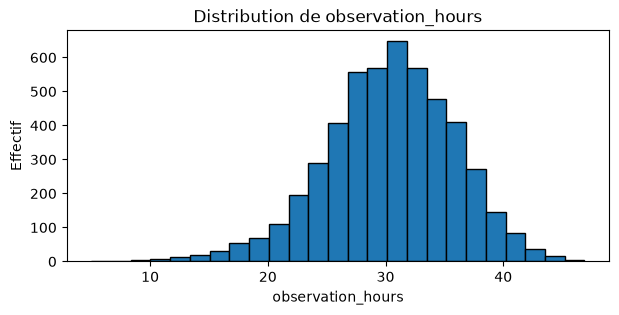

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


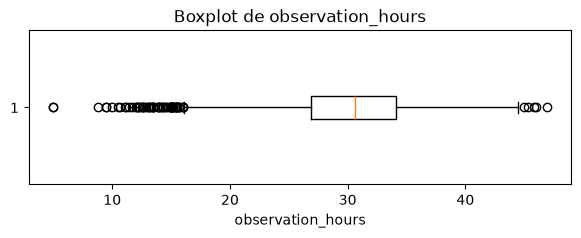

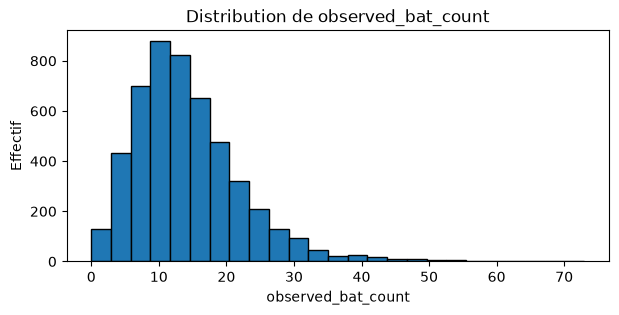

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


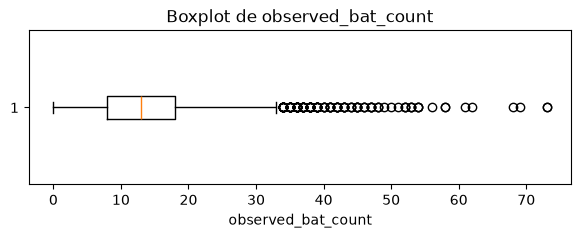

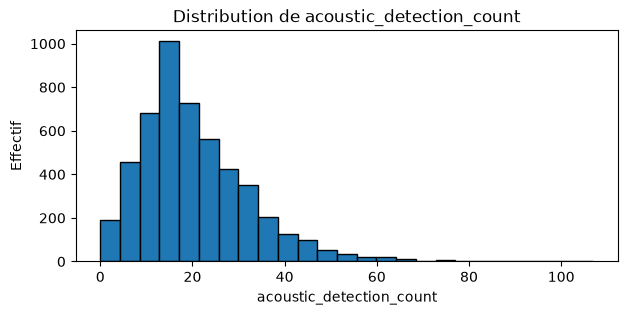

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


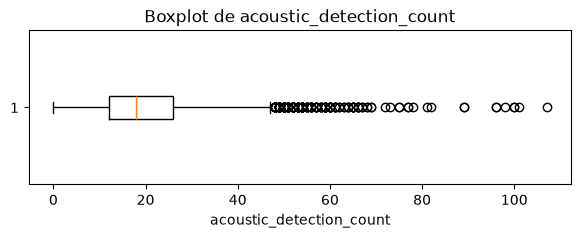

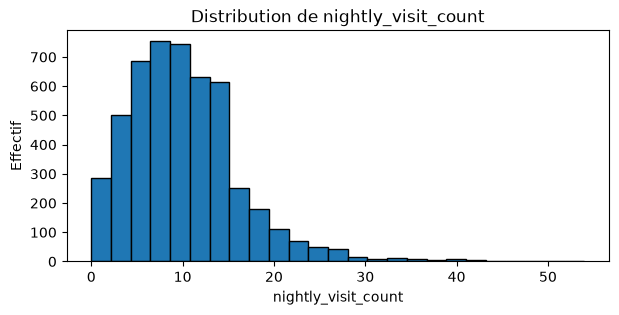

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


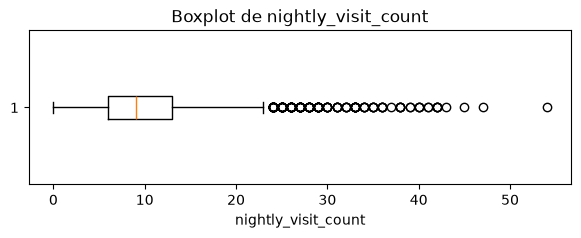

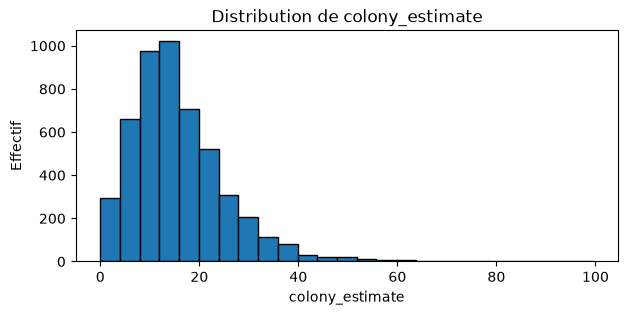

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


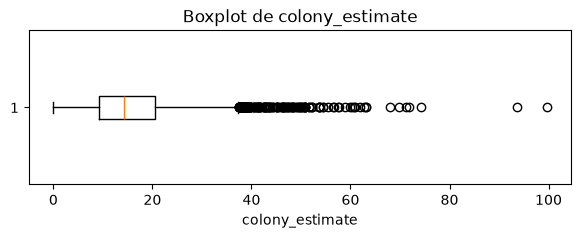

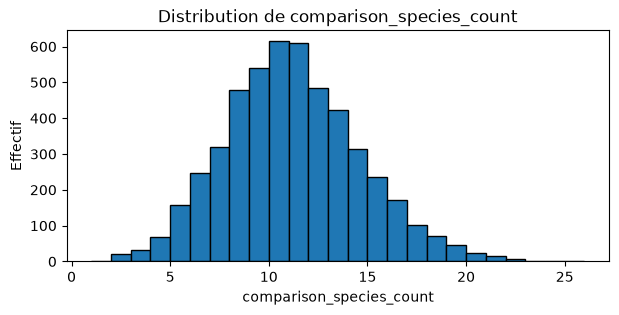

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


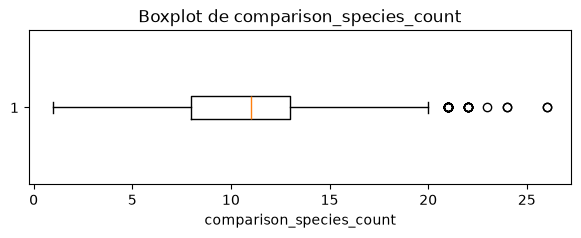

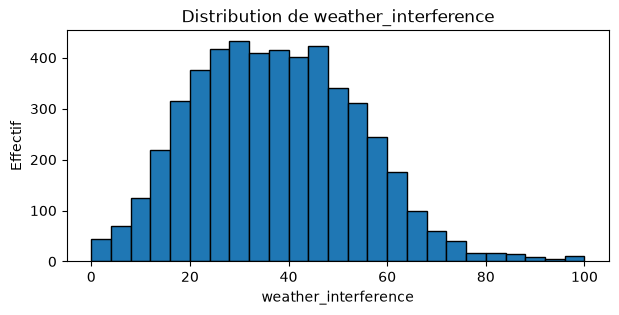

C:\Users\Admin\AppData\Local\Temp\ipykernel_1072\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


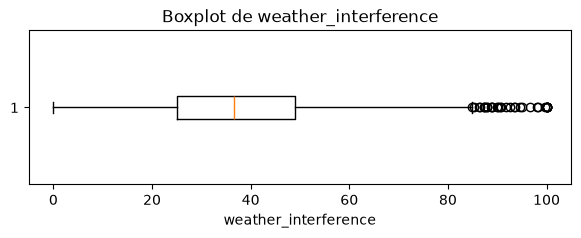

In [115]:
for col in colonnes_numeriques:
    valeurs = df_clean[col].dropna()
    if valeurs.empty:
        continue
    plt.figure(figsize=(7, 3))
    plt.hist(valeurs, bins=25, edgecolor="black")
    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Effectif")
    plt.show()

    plt.figure(figsize=(7, 2))
    plt.boxplot(valeurs, vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

#### Correlation

In [116]:
df_clean[colonnes_numeriques].dtypes

observation_hours           Float64
observed_bat_count            Int64
acoustic_detection_count      Int64
nightly_visit_count           Int64
colony_estimate             Float64
comparison_species_count      Int64
weather_interference        Float64
dtype: object

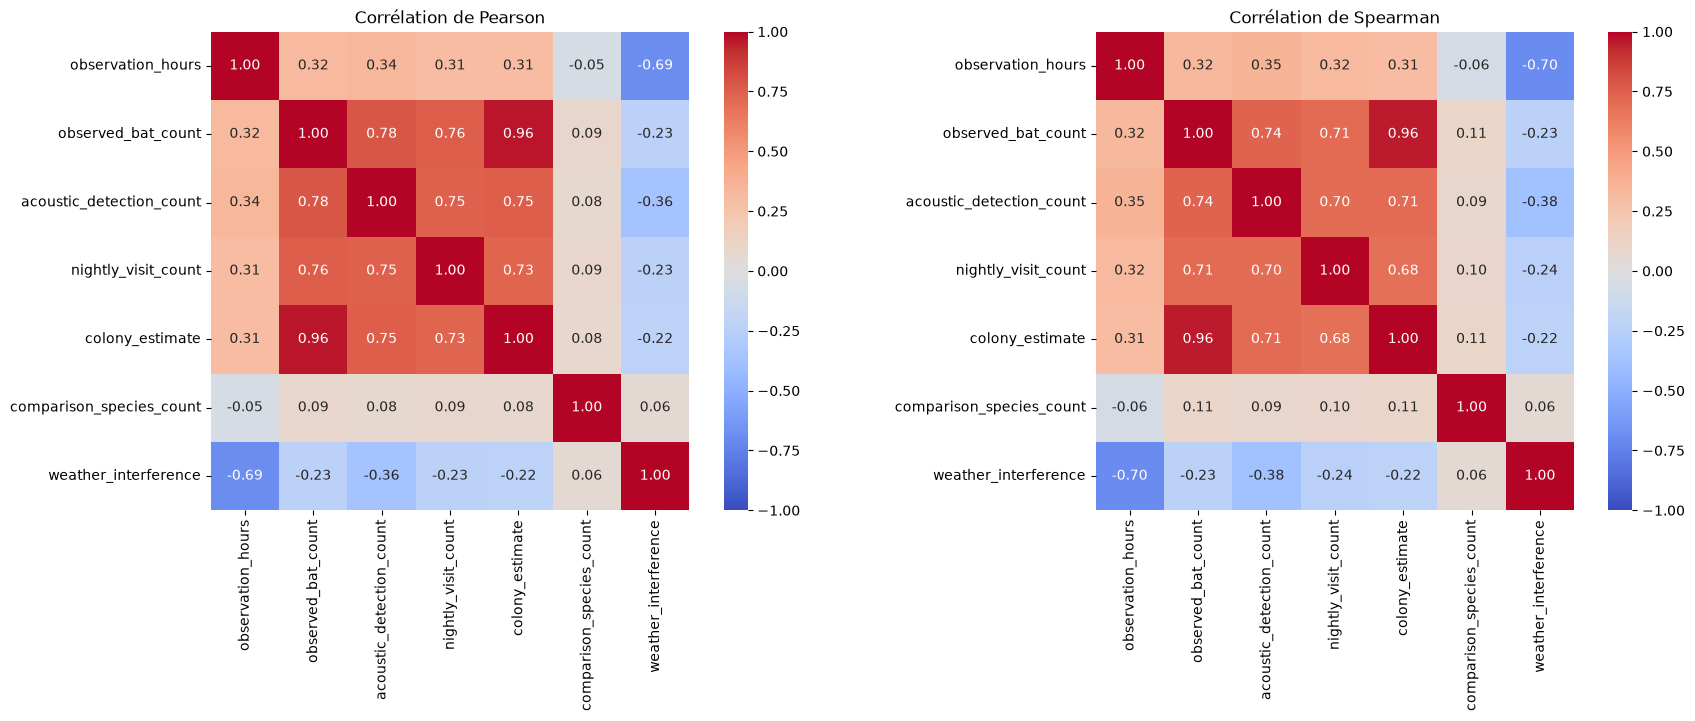

In [117]:
colonnes_numeriques = [
    "observation_hours",
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "colony_estimate",
    "comparison_species_count",
    "weather_interference"
]

corr_pearson = df_clean[colonnes_numeriques].corr(method="pearson")
corr_spearman = df_clean[colonnes_numeriques].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Corrélation de Pearson")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title("Corrélation de Spearman")

plt.tight_layout()
plt.show()

forte corrélation entre : observed_bat_count / acoustic_detection_count / nightly_visit_count / colony_estimate

Scatter plot


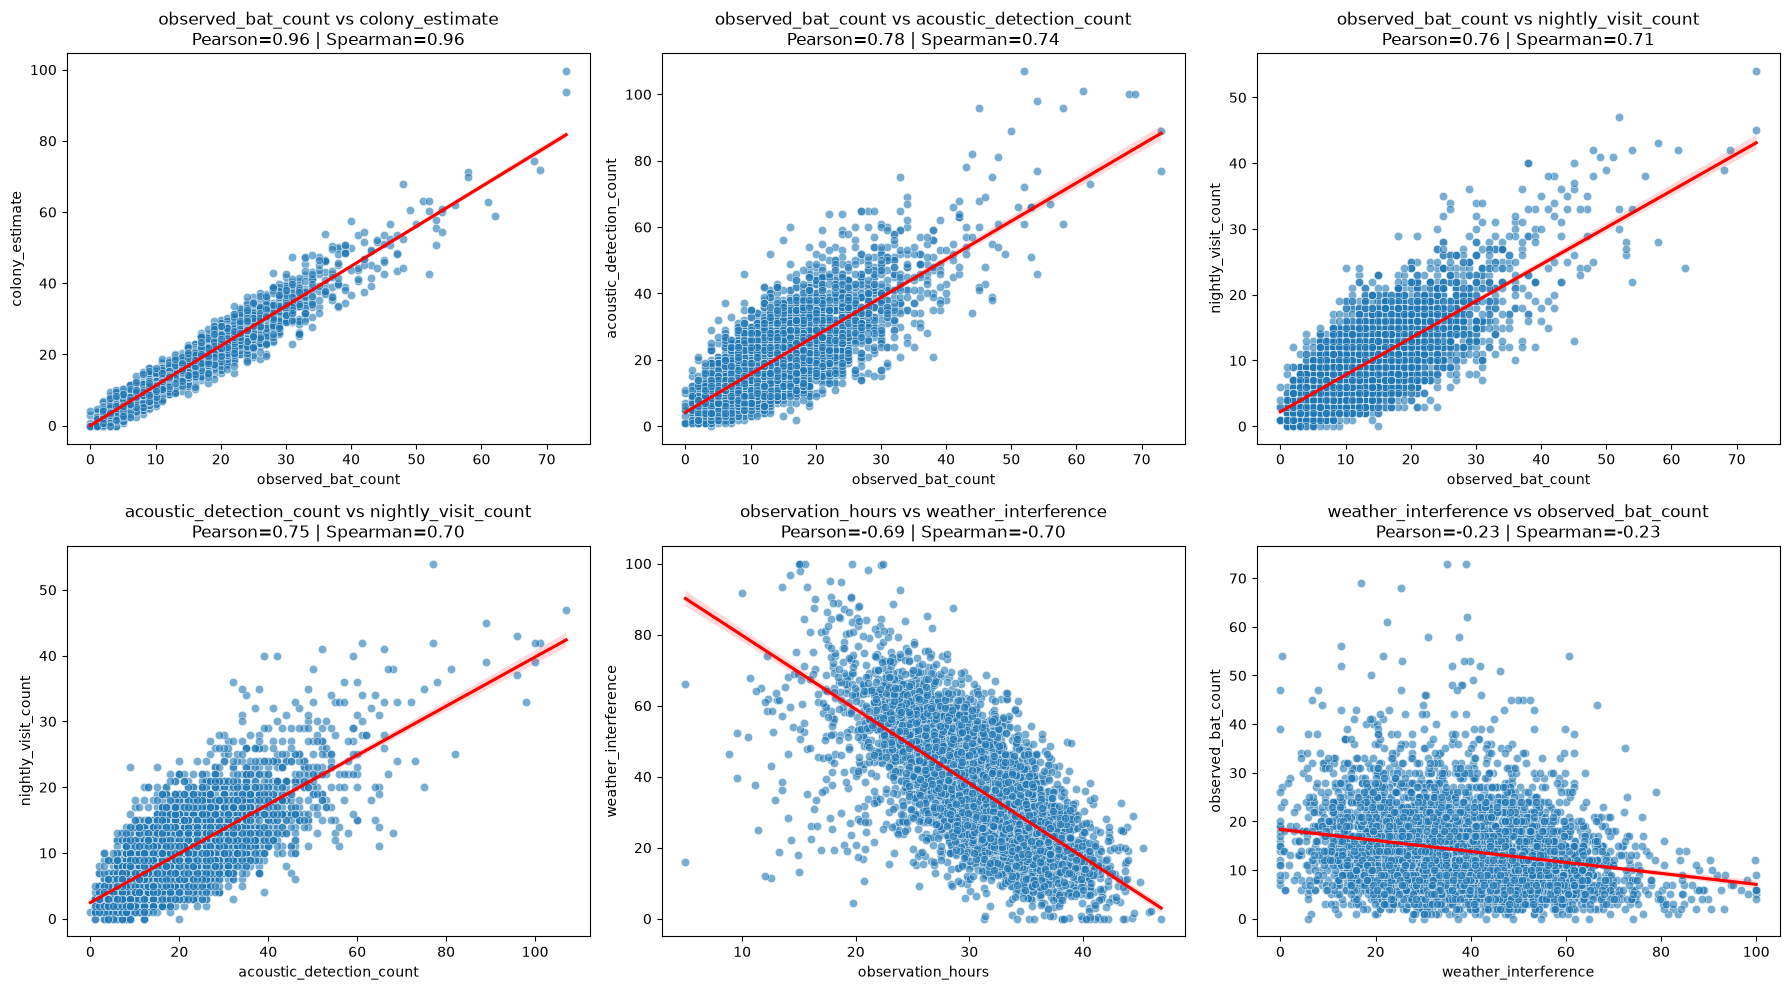

In [118]:
paires = [
    ("observed_bat_count", "colony_estimate"),
    ("observed_bat_count", "acoustic_detection_count"),
    ("observed_bat_count", "nightly_visit_count"),
    ("acoustic_detection_count", "nightly_visit_count"),
    ("observation_hours", "weather_interference"),
    ("weather_interference", "observed_bat_count"),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (x, y) in enumerate(paires):
    sns.scatterplot(data=df_clean, x=x, y=y, ax=axes[i], alpha=0.6)
    sns.regplot(data=df_clean, x=x, y=y, scatter=False, color="red", ax=axes[i])
    
    p = corr_pearson.loc[x, y]
    s = corr_spearman.loc[x, y]
    axes[i].set_title(f"{x} vs {y}\nPearson={p:.2f} | Spearman={s:.2f}")

plt.tight_layout()
plt.show()

une forte cohérence entre les différents indicateurs d’activité (nombre de chauves-souris, détections acoustiques, visites nocturnes et estimation des colonies). On observe aussi un lien négatif prononcé entre les interférences météorologiques et la durée d’observation.

## Export des données nettoyées

In [120]:
print("===== BILAN FINAL DU NETTOYAGE =====")

print("Lignes initiales :", len(df))
print("Lignes finales :", len(df_clean))
print("Doublons exacts :", df_clean.duplicated().sum())

print("\nValeurs manquantes restantes :")
display(df_clean.isna().sum().to_frame("Nombre"))

print("\nTypes des colonnes :")
display(df_clean.dtypes.to_frame("Type"))

===== BILAN FINAL DU NETTOYAGE =====
Lignes initiales : 4994
Lignes finales : 4992
Doublons exacts : 0

Valeurs manquantes restantes :


,Nombre
survey_id,0
site_code,0
survey_start,0
survey_end,0
survey_method,0
observation_hours,0
observed_bat_count,0
acoustic_detection_count,0
nightly_visit_count,0
colony_estimate,0



Types des colonnes :


,Type
survey_id,str
site_code,string
survey_start,datetime64[us]
survey_end,datetime64[us]
survey_method,string
observation_hours,Float64
observed_bat_count,Int64
acoustic_detection_count,Int64
nightly_visit_count,Int64
colony_estimate,Float64


In [121]:
df_clean.to_csv("bat_surveys_clean.csv", index=False)
print("Fichier créé : bat_surveys_clean.csv")

Fichier créé : bat_surveys_clean.csv
